# 03 – Validation setup

This notebook creates the **measuring tools** shared by every experiment of the team:

| # | what | file written |
|---|---|---|
| 1 | **fixed folds** on the agreed clean training set | `splits/folds.csv` |
| 2 | the **shifted-validation plan**: which alteration each validation image receives | `splits/val_shift_plan.csv` |
| 3 | a check that the shifted validation really looks like the test | – |
| 4 | a test of the whole protocol with a simple model | `experiments_log.csv` |

**Two validations, same images.** K-fold decides **which** images are used for validation; the two versions decide **how they look**:
- **clean:** the images as they are;
- **shifted:** the **same** images with the alterations measured on the test (notebook `02_test_shift_study`): a hue rotation of about ±120° on 28% of them and a mild blur on 20% of them.

Every experiment is evaluated on both. The shifted one is our best estimate of the score on the test, so it is the main selection criterion; the clean one is a sanity check (it must not drop much).

Requires `splits/clean_train.csv` (`01_clean_dataset`) and `outputs/meta.csv` + embeddings (`00_eda`). **Run it once**: the files it writes are shared by the whole team and must not be regenerated afterwards.

## 0. Setup

In [3]:
import colorsys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common as C

plt.rcParams["figure.dpi"] = 80
meta = pd.read_csv(C.OUT / "meta.csv")
clean = pd.read_csv(C.SPLITS / "clean_train.csv")
print("DATA =", C.DATA)
print("clean training set:", clean.keep.sum(), "images")

DATA = /home/elia/ANN-DL-Challenge/data
clean training set: 2996 images


## 1. Fixed folds

"Fixed" means that the assignment image → fold is computed **once**, saved, and **reused identically by every experiment and every team member**. Otherwise a change in score could come from different validation images rather than from the change we made, and the out-of-fold predictions of different models could not be combined.

- **On which images:** the 2,995 images of the agreed clean training set (`keep = True`). The copies were removed, so every image is a distinct galaxy: no grouping is needed.
- **How:** stratified 5-fold (`StratifiedKFold`, fixed seed 42): every fold has the same class proportions as the whole set.
- **The `review` images** (suspicious labels) stay in both training and validation: validation is never filtered.

In [4]:
folds = C.make_folds(clean, n_splits=5, seed=42)
folds.to_csv(C.SPLITS / "folds.csv", index=False)
print(folds.fold.value_counts().sort_index().to_dict())
folds.head()

{0: 600, 1: 599, 2: 599, 3: 599, 4: 599}


,id,label,fold,review,artifact
0,train_00000,3,3,False,False
1,train_00001,2,2,False,False
2,train_00002,9,2,False,False
3,train_00003,1,0,False,False
4,train_00004,9,4,False,False


In [5]:
# check 1: images per class and per fold -> the columns must be similar
pd.crosstab(folds.label.map(lambda c: f"{c} {C.CLASSES[c]}"), folds.fold, margins=True, margins_name="total")

fold,0,1,2,3,4,total
label,,,,,,
0 disturbed,36,36,36,37,37,182
1 merging,62,63,63,63,62,313
2 round smooth,89,89,89,90,89,446
3 in-between smooth,69,69,69,68,68,343
4 cigar,12,11,11,11,11,56
5 barred spiral,69,70,69,69,69,346
6 tight spiral,62,61,62,62,62,309
7 loose spiral,89,89,89,88,89,444
8 edge-on no bulge,48,48,48,48,48,240


In [6]:
# check 2: get_split returns disjoint sets, and every image is in validation exactly once
seen = []
for k in range(5):
    tr_k, va_k = C.get_split(folds, k)
    assert not set(tr_k.id) & set(va_k.id)
    seen += list(va_k.id)
assert sorted(seen) == sorted(folds.id)
tr0, va0 = C.get_split(folds, 0)
print(f"OK. fold 0 -> train {len(tr0)} images, validation {len(va0)} images")

OK. fold 0 -> train 2396 images, validation 600 images


**What to notice.** About 600 validation images per fold, with about 11 *cigar* (class 4) each: the F1 of class 4 on a single fold is **noisy** and should be read mostly on the 5-fold average.

## 2. The shifted-validation plan

Parameters (from `02_test_shift_study`, written in `common.py`):

| alteration | share | how |
|---|---|---|
| colour | **28%** | hue rotation by ±(100–140)°, half in each direction |
| blur | **20%** | Gaussian blur, sigma 0.6–1.0 |

For every image of the clean set (each one is a validation image in exactly one fold) we decide **once and for all**, with a fixed seed, which alteration it receives. The two alterations are drawn independently, so some images get both and about 58% stay untouched, like most of the test.

The plan is saved in `splits/val_shift_plan.csv`; during evaluation the shifted image is rebuilt from it with `C.load_shifted`, so it is **always identical** across experiments.

In [7]:
plan = C.make_shift_plan(folds.id, seed=1234)
plan.to_csv(C.SPLITS / "val_shift_plan.csv", index=False)
plan_idx = plan.set_index("id")

has_col, has_blur = plan.hue_deg != 0, plan.blur_sigma > 0
print(f"images in the plan: {len(plan)}")
print(f"colour only {100*(has_col & ~has_blur).mean():.1f}% | blur only {100*(~has_col & has_blur).mean():.1f}% | "
      f"both {100*(has_col & has_blur).mean():.1f}% | untouched {100*(~has_col & ~has_blur).mean():.1f}%")
# shares per fold: they must be similar, otherwise some folds would be "harder"
plan.assign(fold=folds.set_index("id").fold[plan.id].values, colour=has_col, blur=has_blur) \
    .groupby("fold")[["colour", "blur"]].mean().mul(100).round(1)

images in the plan: 2996
colour only 21.2% | blur only 14.1% | both 6.0% | untouched 58.6%


,colour,blur
fold,,
0,26.8,20.3
1,26.0,20.5
2,29.0,20.9
3,26.2,20.5
4,28.0,18.5


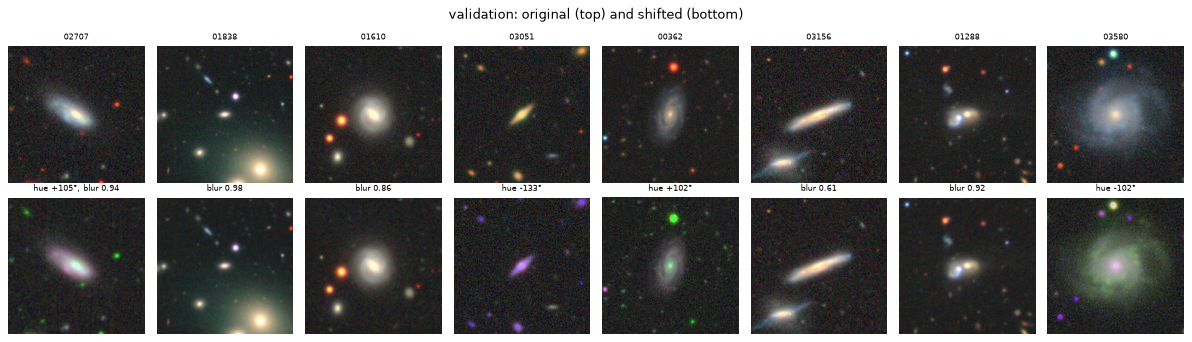

In [8]:
# examples: original on top, shifted version below
ex = plan[has_col | has_blur].sample(8, random_state=1)
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for j, r in enumerate(ex.itertuples()):
    axes[0, j].imshow(C.load_image(r.id)); axes[0, j].set_title(r.id[6:], fontsize=7)
    axes[1, j].imshow(C.load_shifted(r.id, plan_idx))
    what = ([f"hue {r.hue_deg:+.0f}°"] if r.hue_deg else []) + ([f"blur {r.blur_sigma:.2f}"] if r.blur_sigma else [])
    axes[1, j].set_title(", ".join(what), fontsize=7)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("validation: original (top) and shifted (bottom)"); plt.tight_layout(); plt.show()

## 3. Does the shifted validation look like the test?

We measure the shifted validation with **the same two statistics** used in `02_test_shift_study` and compare it with the test and with the clean validation:
- **colour:** share of images with a visibly tinted core (core green share outside the 1–99% range of the clean training set) and the purple / green split;
- **blur:** quantiles of the share of fine detail in the image centre.

We use fold 0 (~600 images); the other folds have the same plan statistics.

In [9]:
def core_rgb(img):
    a = np.asarray(img, np.float32)[80:176, 80:176].reshape(-1, 3)
    L = a.sum(1)
    return a[L >= np.quantile(L, 0.9)].mean(0)

def green_share(rgb):
    return rgb[:, 1] / (rgb.sum(1) + 1e-6)

def detail_ratio(img):
    g = np.asarray(img.convert("L"), np.float32)[64:192, 64:192]
    F = np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean()))) ** 2
    y, x = np.indices(F.shape)
    r = np.hypot(y - 64, x - 64)
    return F[(r > 16) & (r < 40)].sum() / F[(r > 2) & (r <= 16)].sum()

core = pd.read_csv(C.OUT / "core_rgb.csv").set_index("id")        # written by 02_test_shift_study
cg_train = green_share(core.loc[folds.id].to_numpy())
lo, hi = np.quantile(cg_train, [0.01, 0.99])

va_clean = [C.load_image(i) for i in va0.id]
va_shift = [C.load_shifted(i, plan_idx) for i in va0.id]
test_ids = meta[meta.split == "test"].sample(1500, random_state=0).id

def describe(cg, details):
    tinted = (cg < lo) | (cg > hi)
    return {"tinted %": 100 * tinted.mean(),
            "purple share of tinted": (cg < lo).sum() / max(tinted.sum(), 1),
            **{f"detail {q}th pct": np.quantile(details, q / 100) for q in (5, 10, 25, 50, 75)}}

pd.DataFrame({
    "clean validation": describe(green_share(np.array([core_rgb(x) for x in va_clean])), [detail_ratio(x) for x in va_clean]),
    "shifted validation": describe(green_share(np.array([core_rgb(x) for x in va_shift])), [detail_ratio(x) for x in va_shift]),
    "test": describe(green_share(core.loc[meta[meta.split == "test"].id].to_numpy()),
                     [detail_ratio(C.load_image(i)) for i in test_ids]),
}).round(3)

,clean validation,shifted validation,test
tinted %,1.333,19.667,21.838
purple share of tinted,0.375,0.619,0.582
detail 5th pct,0.052,0.035,0.027
detail 10th pct,0.065,0.050,0.041
detail 25th pct,0.091,0.076,0.071
detail 50th pct,0.134,0.128,0.119
detail 75th pct,0.205,0.203,0.195


**How to read it.** The **shifted** column is close to the **test** column and clearly different from the **clean** one:
- **colour:** ≈ 20% of visibly tinted cores (test ≈ 22%; fold 0 received 26% of rotated images, slightly below the 28% average, which explains the small gap), against 1.5% in the clean validation. The purple share (≈ 0.5 vs 0.58) is a bit lower, a minor difference;
- **blur:** the lower tail of the detail distribution (5th–25th percentiles) becomes softer, like in the test, while the median and upper quantiles stay almost unchanged.

## 4. Testing the whole protocol

Before using these tools with a CNN, we try them with the simplest possible model: the **linear probe** of the EDA (logistic regression on frozen DINOv2 embeddings), on **fold 0**. The flow is the one every experiment will follow:

1. `C.get_split(folds, 0)` → training and validation images;
2. train the model on the training images;
3. evaluate on the **clean** and on the **shifted** validation with `C.evaluate`;
4. append a row to the **experiment log** (`experiments_log.csv`).

In [10]:
import torch, timm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

E = np.load(C.OUT / "emb_dinov2_s.npy")
row_of = {i: k for k, i in enumerate(pd.read_csv(C.OUT / "emb_dinov2_s_ids.csv").id)}

probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.05))
probe.fit(E[[row_of[i] for i in tr0.id]], tr0.label)
clean_res = C.evaluate(va0.label, probe.predict(E[[row_of[i] for i in va0.id]]))

# embeddings of the SHIFTED validation images (same model and preprocessing as in the EDA)
dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
model = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, num_classes=0, img_size=224).eval().to(dev)
cfg = timm.data.resolve_data_config({}, model=model)
tf = timm.data.create_transform(**{**cfg, "input_size": (3, 224, 224), "crop_pct": 1.0})
with torch.no_grad():
    E_shift = np.concatenate([model(torch.stack([tf(x) for x in va_shift[k:k + 128]]).to(dev)).float().cpu().numpy()
                              for k in range(0, len(va_shift), 128)])
shifted_res = C.evaluate(va0.label, probe.predict(E_shift))

print(f"weighted F1  clean: {clean_res['f1_weighted']:.3f}   shifted: {shifted_res['f1_weighted']:.3f}")
pd.DataFrame({"clean": clean_res["f1_per_class"], "shifted": shifted_res["f1_per_class"]}).round(3)

weighted F1  clean: 0.622   shifted: 0.589


,clean,shifted
0 disturbed,0.291,0.295
1 merging,0.547,0.513
2 round smooth,0.769,0.780
3 in-between smooth,0.662,0.675
4 cigar,0.353,0.471
5 barred spiral,0.606,0.533
6 tight spiral,0.587,0.569
7 loose spiral,0.492,0.427
8 edge-on no bulge,0.804,0.731
9 edge-on bulge,0.774,0.690


In [12]:
# experiment log: one row per experiment, appended, never overwritten
log_file = C.HERE / "experiments_log.csv"
row = {"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "fold": 0, "train_set": "clean (keep=True)",
       **C.summary_row("linear probe DINOv2-S (frozen)", clean_res, shifted_res), "kaggle": None,
       "note": "reference for the protocol"}
log = pd.concat([pd.read_csv(log_file), pd.DataFrame([row])]) if log_file.exists() else pd.DataFrame([row])
log = log.drop_duplicates(subset=["experiment", "fold", "train_set"], keep="last")
log.to_csv(log_file, index=False)
log

,date,fold,train_set,experiment,f1_clean,f1_shifted,f1_cigar_clean,f1_cigar_shifted,kaggle,note
0,2026-11-26 17:25,0,clean (keep=True),linear probe DINOv2-S (EDA),0.6217,0.6265,0.3529,0.3750,NaN,phase 1 reference
0,2026-11-26 20:52,0,clean (keep=True),linear probe DINOv2-S (frozen),0.6217,0.5889,0.3529,0.4706,None,reference for the protocol


**Reading.** Even the frozen DINOv2 probe loses ≈ 0.03 of weighted F1 on the shifted validation, although DINOv2 was trained with colour and blur augmentations and is partly invariant to them; class 4 (*cigar*) suffers most (but with ~11 images its F1 is very noisy). A CNN **fine-tuned** on our training set, which never sees rotated hues or blurred images, can lose much more: that is exactly what the shifted validation is for, and what colour / blur augmentation should fix.

## Summary and rules

| what | value |
|---|---|
| folds | 5, stratified by class, seed 42, on the 2,995 clean images (~600 per fold, ~11 *cigar* per fold) → `splits/folds.csv` |
| shifted validation | same images; hue rotation ±(100–140)° on 28%, blur sigma 0.6–1.0 on 20%, seed 1234 → `splits/val_shift_plan.csv` |

**Rules for every experiment of the team:**
1. read the split from `splits/folds.csv` with `C.get_split`; **never** recompute it;
2. **never filter the validation**: experiments only change the training set;
3. evaluate every model on **both** validations with `C.evaluate` (shifted images via `C.load_shifted`) and append a row to `experiments_log.csv`;
4. **selection rule:** the shifted validation decides (improvement ≥ ~0.01); the clean one must not drop by more than ~0.01; the F1 of class 4 must not collapse;
5. explore on **fold 0**; confirm important decisions on **all 5 folds** and with a Kaggle submission;
6. for models run on all 5 folds, save the **out-of-fold** probabilities (2,995 × 10) so that models of different team members can be compared and combined.